# Math 189M Assignment #7 — Lab: Actor Ranking (Not Kevin Bacon)

**Name:** 

**Collaborators:** 

**Goal.** Use power iteration on the "random surfer" matrix $R = pB + \frac{1-p}{n}\mathbf{1}\mathbf{1}^T$ to rank actors by how likely a random walk on the collaboration network is to visit them. We never form $R$; we only apply it via $y = pBx + \frac{1-p}{n}\mathbf{1}$.

In [9]:
import Pkg; Pkg.add("MAT")

using MAT, SparseArrays, LinearAlgebra, Plots

    Updating registry at `~/.julia/registries/General.toml`
    Updating `~/Documents/GitHub/Math-189M-NumericalLinearAlgebra/Project.toml`
⌅ [23992714] + MAT v0.11.5
    Manifest No packages added to or removed from `~/Documents/GitHub/Math-189M-NumericalLinearAlgebra/Manifest.toml`


# (a) Load the data

In [10]:
data = matread("actornetwork.mat")
actor = data["actor"]   # vector of actor names
A = data["A"]           # sparse symmetric adjacency matrix
M = data["M"]           # used in the Discussion questions (not needed here)

n = size(A, 1)
println("Number of actors: n = ", n)
println("Type of A: ", typeof(A))

Number of actors: n = 81291
Type of A: SparseMatrixCSC{Float64, Int64}


# (b) Density and memory usage

In [11]:
density = nnz(A) / n^2
sparse_bytes = Base.summarysize(A)
full_bytes = n^2 * 8          # equivalent dense Float64 matrix (never constructed)

println("Nonzeros:             ", nnz(A))
println("Density:              ", density)
println("Sparse storage:       ", sparse_bytes, " bytes  (≈ ", round(sparse_bytes/1e6, digits=2), " MB)")
println("Full Float64 storage: ", full_bytes, " bytes  (≈ ", round(full_bytes/1e9, digits=2), " GB)")
println("Ratio full/sparse:    ", round(full_bytes / sparse_bytes, digits=1))

Nonzeros:             2753961
Density:              0.00041674735643046265
Sparse storage:       44713872 bytes  (≈ 44.71 MB)
Full Float64 storage: 52865813448 bytes  (≈ 52.87 GB)
Ratio full/sparse:    1182.3


**Commentary.** *(Fill in: the matrix is extremely sparse, so sparse storage is orders of magnitude smaller than the dense equivalent, which would not realistically fit in memory.)*

# (c) Number of connections per actor

min s = 1.0,  max s = 1069.0,  mean s = 33.87780935158874
Actors with no connections (s_i = 0): 0


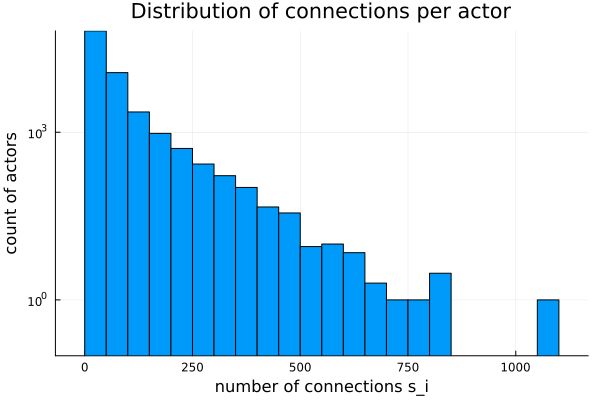

In [17]:
s = vec(sum(A, dims=2))   # s[i] = number of actors that actor i connects to

println("min s = ", minimum(s), ",  max s = ", maximum(s), ",  mean s = ", sum(s)/n)
println("Actors with no connections (s_i = 0): ", count(==(0), s))

histogram(s, bins=32, legend=false,yaxis=:log10,
          xlabel="number of connections s_i", ylabel="count of actors",
          title="Distribution of connections per actor")

**Commentary.** *(Fill in: describe the shape — most actors have few connections, with a long tail of highly connected actors. Optionally try `yaxis=:log10` to see the tail better.)*

# (d) Construct $B$

We need $B_{ij} = A_{ji}/s_j$. Since $A$ is symmetric, $A_{ji} = A_{ij}$, so $B_{ij} = A_{ij}/s_j$. That is just $A$ with column $j$ scaled by $1/s_j$, i.e. $B = A\,\mathrm{diag}(1/s)$. This avoids looping over all elements and keeps $B$ sparse.

(If any actor had $s_j = 0$, we would divide by zero; the check below guards against that by using $0$ for those columns.)

In [13]:
sinv = [si > 0 ? 1/si : 0.0 for si in s]
B = A * spdiagm(0 => sinv)

println("B is ", typeof(B), " with ", nnz(B), " nonzeros")
println("Column sums of B (should be 1 for every actor with s_j > 0): ",
        extrema(vec(sum(B, dims=1))[s .> 0]))

B is SparseMatrixCSC{Float64, Int64} with 2753961 nonzeros
Column sums of B (should be 1 for every actor with s_j > 0): (0.9999999999999977, 1.0000000000000016)


# (e) Power iteration with $p = 0.9$

We apply $y = pBx + \frac{1-p}{n}\mathbf{1}$ directly; $R$ is never formed. No normalization step is needed because the map preserves $\|x\|_1 = 1$.

In [14]:
p = 0.9
x = rand(n)            # positive random entries
x ./= sum(x)           # normalize so that ||x||_1 = 1

diffs = zeros(100)     # record ||x_{k+1} - x_k||_1 for plotting
xprev = copy(x)
for k in 1:100
    xprev = x
    x = p * (B * x) .+ (1 - p) / n     # equation (3): Rx without forming R
    diffs[k] = norm(x - xprev, 1)
end
# now x = x_101 and xprev = x_100

println("||x101 - x100||_1 = ", norm(x - xprev, 1))
println("Less than 1e-6?    ", norm(x - xprev, 1) < 1e-6)
println("||x101||_1 = ", sum(x), "  (should be ≈ 1)")

||x101 - x100||_1 = 7.132147875388669e-8
Less than 1e-6?    true
||x101||_1 = 0.9999999999999998  (should be ≈ 1)


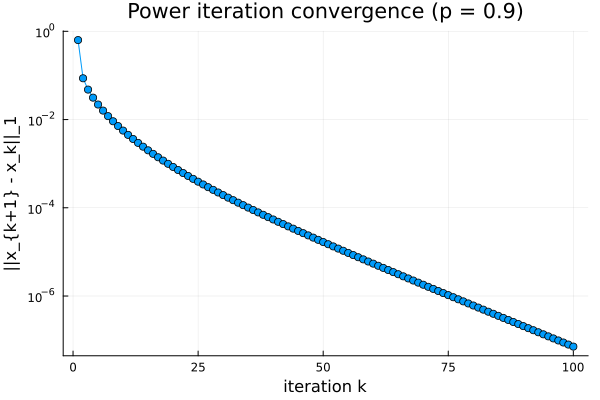

In [15]:
plot(1:100, diffs, yscale=:log10, marker=:circle, legend=false,
     xlabel="iteration k", ylabel="||x_{k+1} - x_k||_1",
     title="Power iteration convergence (p = 0.9)")

**Commentary.** *(Fill in: the differences decay geometrically, a straight line on the semilog plot. The rate is governed by $|\lambda_2/\lambda_1|$, which is at most $p = 0.9$ for this matrix.)*

# (f) The 10 "most collaborative" actors

In [16]:
idx = sortperm(x, rev=true)
for r in 1:10
    println(lpad(r, 2), ". ", actor[idx[r]], "   (x = ", round(x[idx[r]], sigdigits=4), ", connections = ", Int(s[idx[r]]), ")")
end

 1. Danny Trejo   (x = 0.0003151, connections = 1069)
 2. Richard Riehle   (x = 0.000233, connections = 831)
 3. Eric Roberts   (x = 0.0002286, connections = 779)
 4. Michael Madsen   (x = 0.0002264, connections = 749)
 5. Keith David   (x = 0.0002246, connections = 817)
 6. Tom Arnold   (x = 0.0002121, connections = 800)
 7. Clifton Powell   (x = 0.0001865, connections = 621)
 8. Melissa Leo   (x = 0.0001824, connections = 621)
 9. James Franco   (x = 0.0001773, connections = 646)
10. David Koechner   (x = 0.0001736, connections = 669)


**Commentary.** *(Fill in: do the top-ranked actors match the actors with the most connections $s_i$? Note that the ranking reflects connections to *well-connected* actors, not just raw counts.)*

# (g) Connection to the course (ungraded)

*Draft talking points — rewrite in your own words:*

- **Power iteration (Lecture 16):** repeatedly applying $R$ converges to the dominant eigenvector (eigenvalue $\lambda = 1$), and the convergence rate depends on the gap $|\lambda_2|/|\lambda_1|$.
- **Exploiting structure:** $R$ is dense, but $Rx = pBx + \frac{1-p}{n}\mathbf{1}$ costs only $O(\mathrm{nnz}(B))$ per step, so an $n \times n$ dense matrix never needs to be stored or multiplied.
- **Takeaway:** the leading eigenvector of a well-chosen matrix encodes a global notion of importance (the idea behind PageRank), and iterative methods that only need matrix-vector products make that tractable at scale.